# Praktikum 2: parameter dan evaluasi HDBSCAN

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import hdbscan
from sklearn.cluster import DBSCAN

def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(X[ci, 0], X[ci, 1], 'x' if k == -1 else 'o',
                    markerfacecolor=tuple(col), markeredgecolor='k',
                    markersize=4 if k == -1 else 1 + 5 * proba_map[ci])
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = 'Label pembanding' if ground_truth else 'Estimated'
    title = f'{preamble} number of clusters: {n_clusters_}'
    if parameters is not None:
        title += ' | ' + ', '.join(f'{k}={v}' for k, v in parameters.items())
    ax.set_title(title)
    plt.tight_layout()

import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['latitude', 'longitude']].to_numpy()
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]

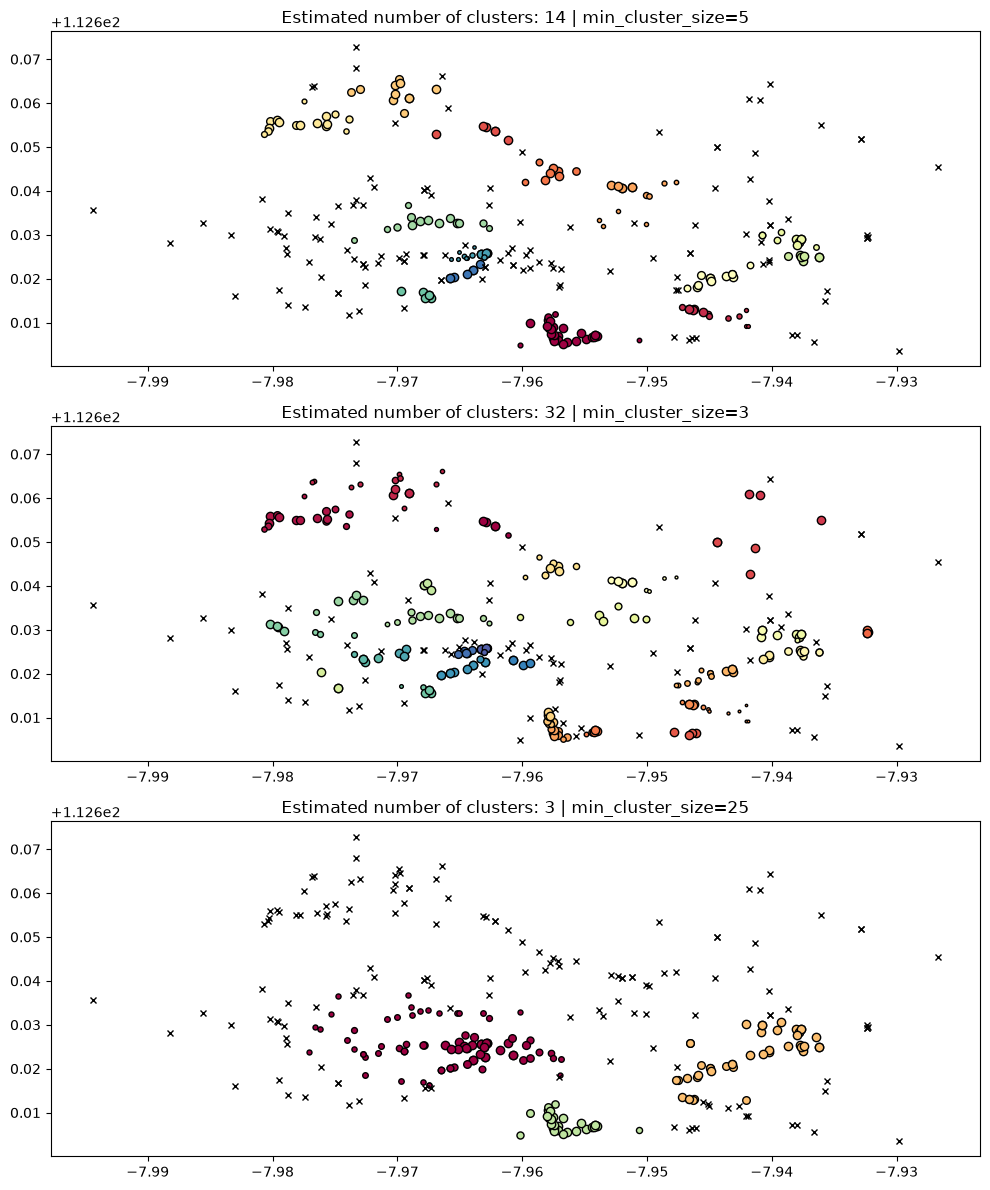

In [2]:
# Langkah 7: Eksperimen Hyperparameter min_cluster_size

PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

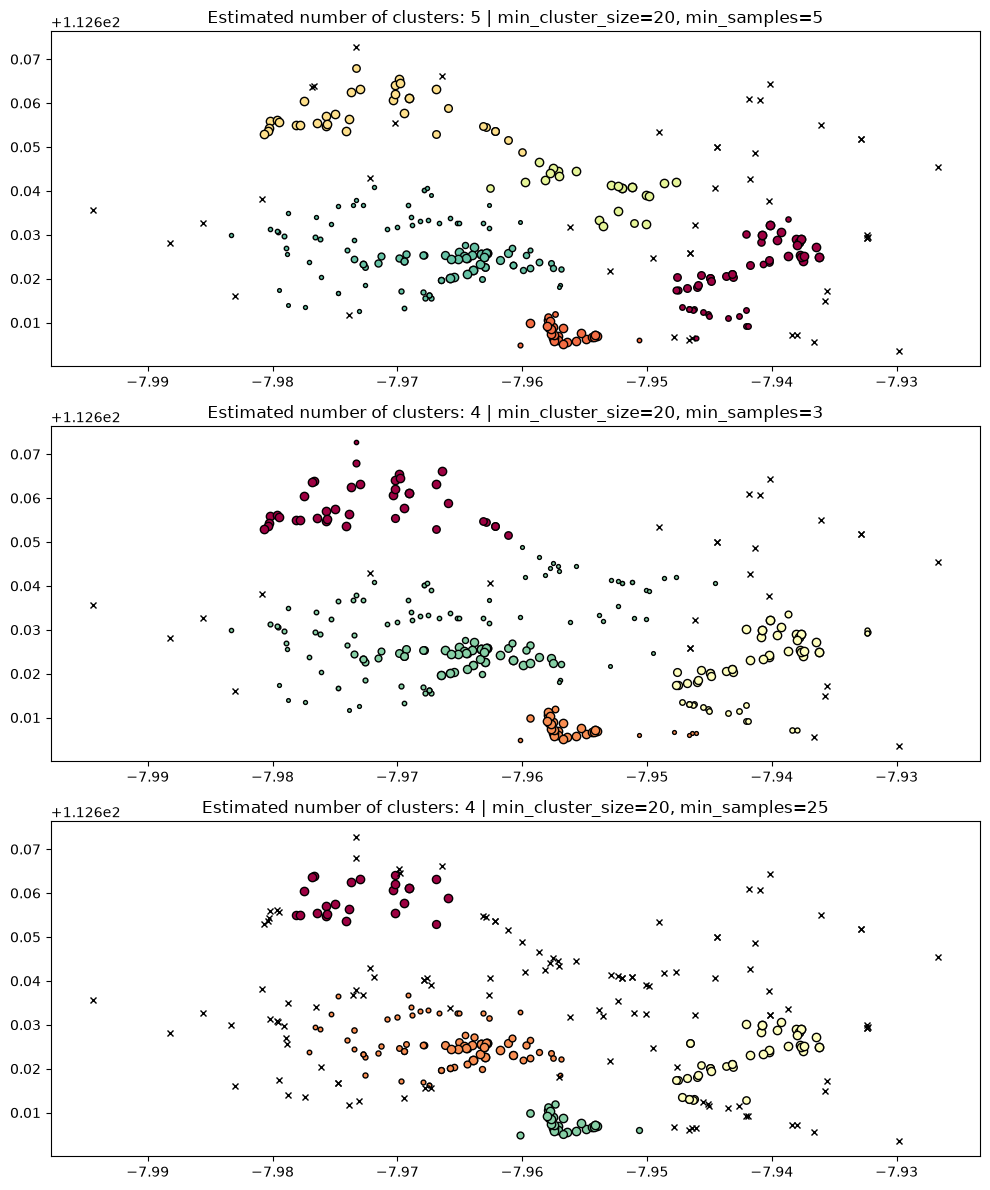

In [3]:
# Langkah 8: Eksperimen Hyperparameter min_samples

PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

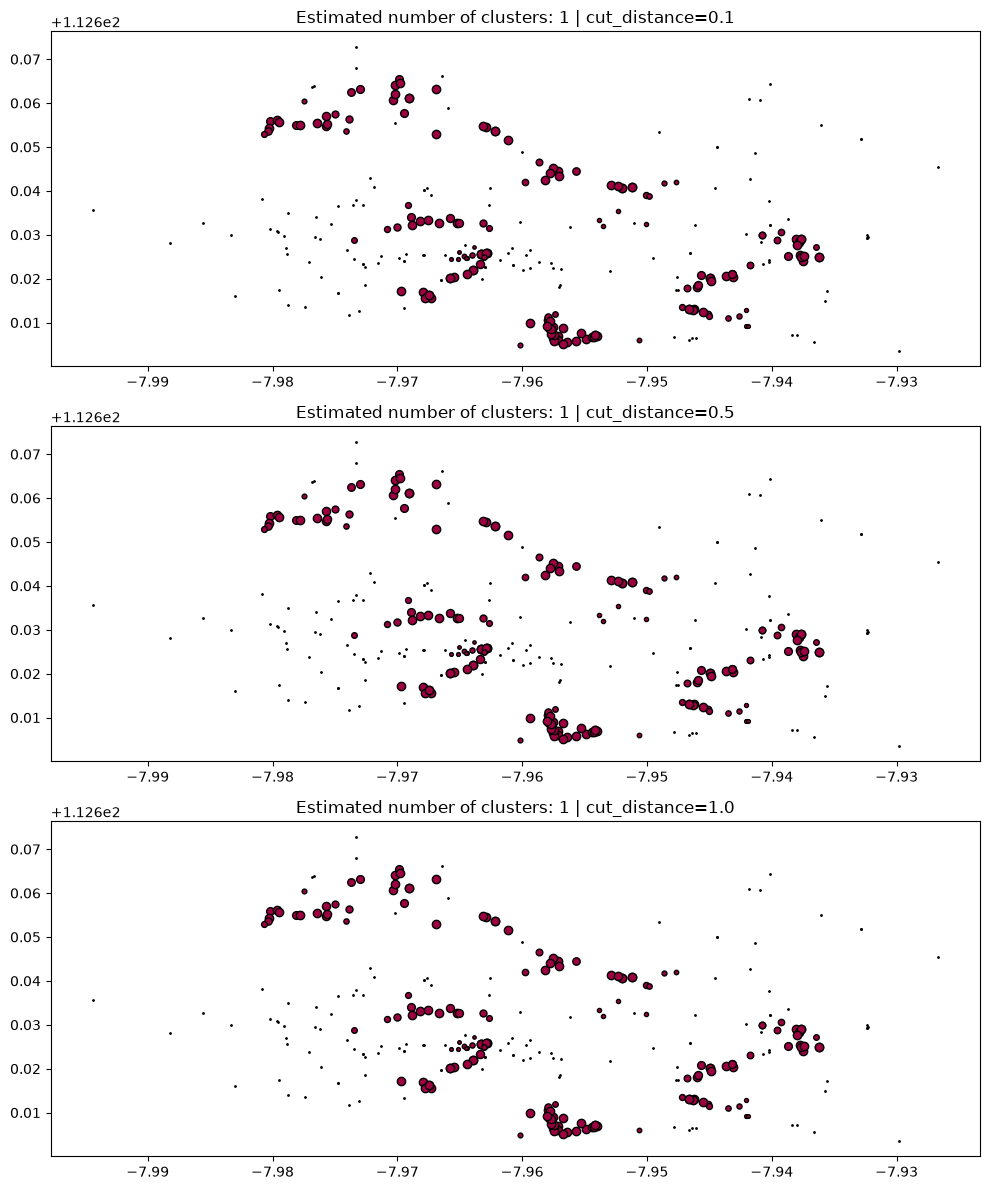

In [4]:
# Langkah 9: DBSCAN Clustering dari Pohon HDBSCAN

PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

In [5]:
# Langkah 10: Evaluasi silhouette
from sklearn.metrics import silhouette_score
sil_score = silhouette_score(X, hdb.labels_) if 1 < len(set(hdb.labels_)) < len(X) else float('nan')
print('Silhouette:', sil_score)

Silhouette: 0.06320834968449793


In [6]:
# Langkah 11: Evaluasi Davies-Bouldin
from sklearn.metrics import davies_bouldin_score
dbi_score = davies_bouldin_score(X, hdb.labels_) if 1 < len(set(hdb.labels_)) < len(X) else float('nan')
print('Davies-Bouldin:', dbi_score)

Davies-Bouldin: 1.547164547975477


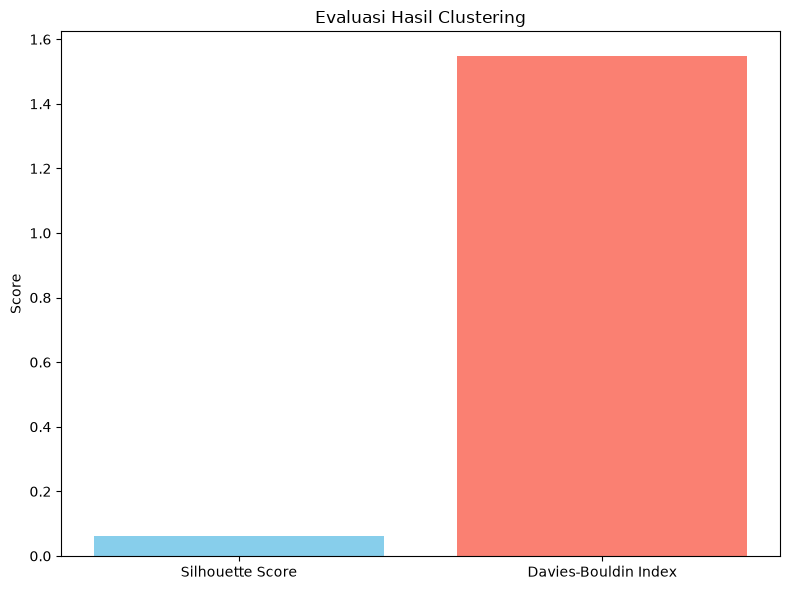

In [7]:
# Langkah 12: Visualisasi Hasil Evaluasi

# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()